Demand Analysis

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from pathlib import Path
from sklearn.preprocessing import MinMaxScaler
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'figure.facecolor': 'white',
    'axes.facecolor': '#F9F9F9',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'font.family': 'sans-serif',
    'axes.titlesize': 13,
    'axes.labelsize': 11,
})

BLUE   = '#1B4F8A'
RED    = '#C0392B'
GREEN  = '#27AE60'
ORANGE = '#E67E22'
GREY   = '#95A5A6'

FIGURES   = Path('/content/figures')
PROCESSED = Path('/content/processed')
FIGURES.mkdir(exist_ok=True)
PROCESSED.mkdir(exist_ok=True)

from google.colab import files

print("Upload listings_clean.csv")
up = files.upload()
listings = pd.read_csv('listings_clean.csv', low_memory=False)

# Pick the borough column that actually has non-null data
if ('neighbourhood_group_cleansed' in listings.columns
        and listings['neighbourhood_group_cleansed'].notna().sum() > 0):
    borough_col = 'neighbourhood_group_cleansed'
else:
    borough_col = 'neighbourhood_cleansed'

print(f"Listings loaded : {len(listings):,}")
print(f"Borough column  : {borough_col}  ({listings[borough_col].nunique()} unique values)")
print(listings[borough_col].value_counts().head(5))


Upload listings_clean.csv


Saving listings_clean.csv to listings_clean.csv
Listings loaded : 59,810
Borough column  : neighbourhood_cleansed  (33 unique values)
neighbourhood_cleansed
Westminster               7931
Kensington and Chelsea    4644
Camden                    4288
Tower Hamlets             3874
Southwark                 3029
Name: count, dtype: int64


Load Reviews

In [3]:
print("Upload reviews.csv.gz")
up2 = files.upload()

reviews = pd.read_csv('reviews.csv.gz',
                      usecols=['listing_id', 'date', 'reviewer_id'],
                      parse_dates=['date'],
                      low_memory=False)

reviews['listing_id'] = reviews['listing_id'].astype(str)

print(f"Reviews loaded  : {len(reviews):,}")
print(f"Date range      : {reviews['date'].min().date()} → {reviews['date'].max().date()}")
print(f"Unique listings : {reviews['listing_id'].nunique():,}")


Upload reviews.csv.gz


Saving reviews.csv.gz to reviews.csv.gz
Reviews loaded  : 2,323,969
Date range      : 2009-12-21 → 2026-09-22
Unique listings : 71,260


Load calendar (availability and price by date)

In [4]:
print("Upload calendar.csv.gz")
up3 = files.upload()

cal = pd.read_csv('calendar.csv.gz',
                  usecols=['listing_id', 'date', 'available'],
                  parse_dates=['date'],
                  low_memory=False)

cal['listing_id'] = cal['listing_id'].astype(str)
cal['is_booked']  = cal['available'] == 'f'   # 'f' = blocked/booked

print(f"Calendar rows   : {len(cal):,}")
print(f"Date range      : {cal['date'].min().date()} → {cal['date'].max().date()}")
print(f"Unique listings : {cal['listing_id'].nunique():,}")


Upload calendar.csv.gz


Saving calendar.csv.gz to calendar.csv.gz
Calendar rows   : 33,563,890
Date range      : 2026-09-18 → 2027-09-22
Unique listings : 91,954


Occupancy rate estimation

In [5]:
print("=" * 65)
print("OCCUPANCY RATE ESTIMATION")
print("=" * 65)

occ = (cal.groupby('listing_id')
          .agg(total_days=('date', 'count'),
               days_booked=('is_booked', 'sum'))
          .reset_index())

occ['occupancy_rate'] = occ['days_booked'] / occ['total_days'].replace(0, np.nan)

listings['id_str'] = listings['id'].astype(str)
listings = listings.merge(occ[['listing_id', 'occupancy_rate', 'days_booked']],
                          left_on='id_str', right_on='listing_id', how='left')
listings.drop(columns='id_str', inplace=True)

print(f"Median occupancy rate : {listings['occupancy_rate'].median()*100:.1f}%")
print(f"Mean occupancy rate   : {listings['occupancy_rate'].mean()*100:.1f}%")
print(f"% listings > 50% occ  : {(listings['occupancy_rate'] > 0.5).mean()*100:.1f}%")
print(f"% listings < 10% occ  : {(listings['occupancy_rate'] < 0.1).mean()*100:.1f}%")


OCCUPANCY RATE ESTIMATION
Median occupancy rate : 29.3%
Mean occupancy rate   : 38.7%
% listings > 50% occ  : 38.5%
% listings < 10% occ  : 28.7%


Estimated annual revenue

Estimated Annual Revenue Distribution:
  25th percentile : £   2,407
  50th percentile : £   6,673
  75th percentile : £  14,292
  90th percentile : £  24,327
  95th percentile : £  33,819


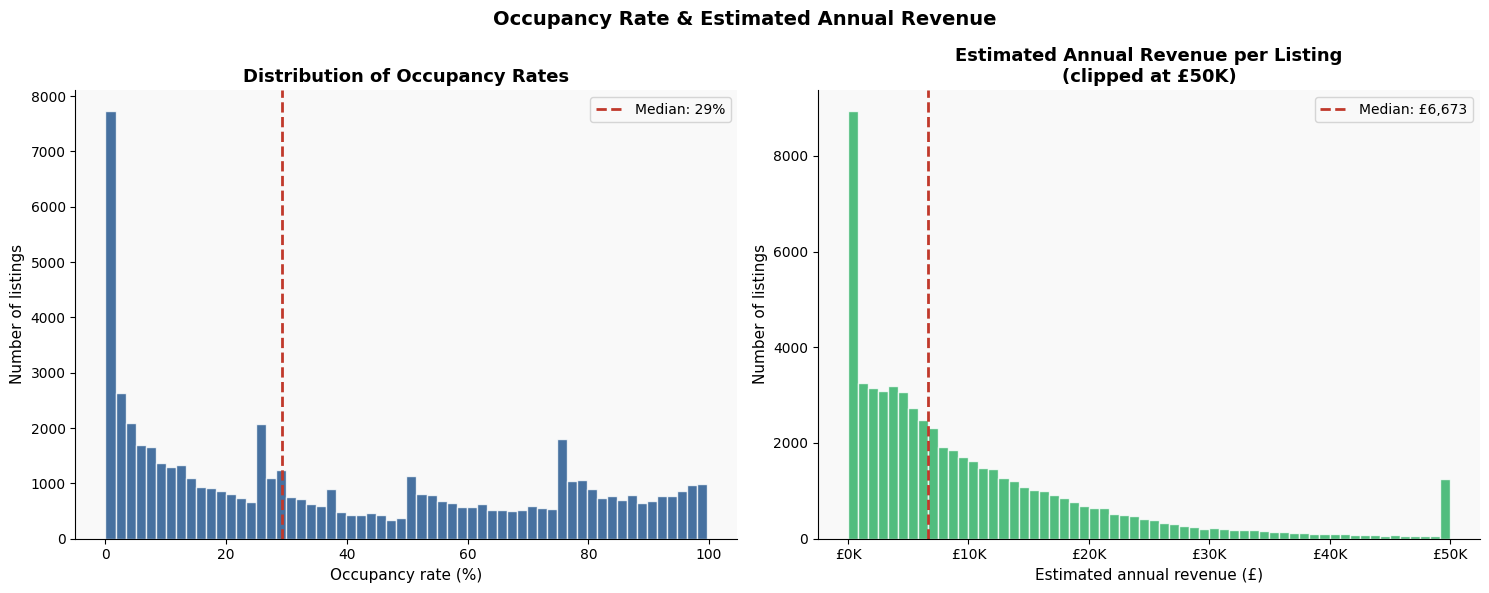

In [6]:
listings['est_annual_revenue'] = (
    listings['occupancy_rate'] *
    listings['availability_365'].clip(lower=1) *
    listings['price']
)

print("Estimated Annual Revenue Distribution:")
for pct in [25, 50, 75, 90, 95]:
    val = listings['est_annual_revenue'].quantile(pct / 100)
    print(f"  {pct}th percentile : £{val:>8,.0f}")

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
fig.suptitle('Occupancy Rate & Estimated Annual Revenue', fontsize=14, fontweight='bold')

axes[0].hist(listings['occupancy_rate'].dropna() * 100,
             bins=60, color=BLUE, alpha=0.8, edgecolor='white', lw=0.3)
axes[0].set_title('Distribution of Occupancy Rates', fontweight='bold')
axes[0].set_xlabel('Occupancy rate (%)')
axes[0].set_ylabel('Number of listings')
axes[0].axvline(listings['occupancy_rate'].median() * 100,
                color=RED, lw=2, linestyle='--',
                label=f"Median: {listings['occupancy_rate'].median()*100:.0f}%")
axes[0].legend()

axes[1].hist(listings['est_annual_revenue'].clip(upper=50000).dropna(),
             bins=60, color=GREEN, alpha=0.8, edgecolor='white', lw=0.3)
axes[1].set_title('Estimated Annual Revenue per Listing\n(clipped at £50K)', fontweight='bold')
axes[1].set_xlabel('Estimated annual revenue (£)')
axes[1].set_ylabel('Number of listings')
axes[1].xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'£{v/1000:.0f}K'))
med_rev = listings['est_annual_revenue'].median()
axes[1].axvline(med_rev, color=RED, lw=2, linestyle='--',
                label=f"Median: £{med_rev:,.0f}")
axes[1].legend()

plt.tight_layout()
plt.savefig(FIGURES / '06_occupancy_revenue.png', dpi=150, bbox_inches='tight')
plt.show()


Seasonal demand from reviews

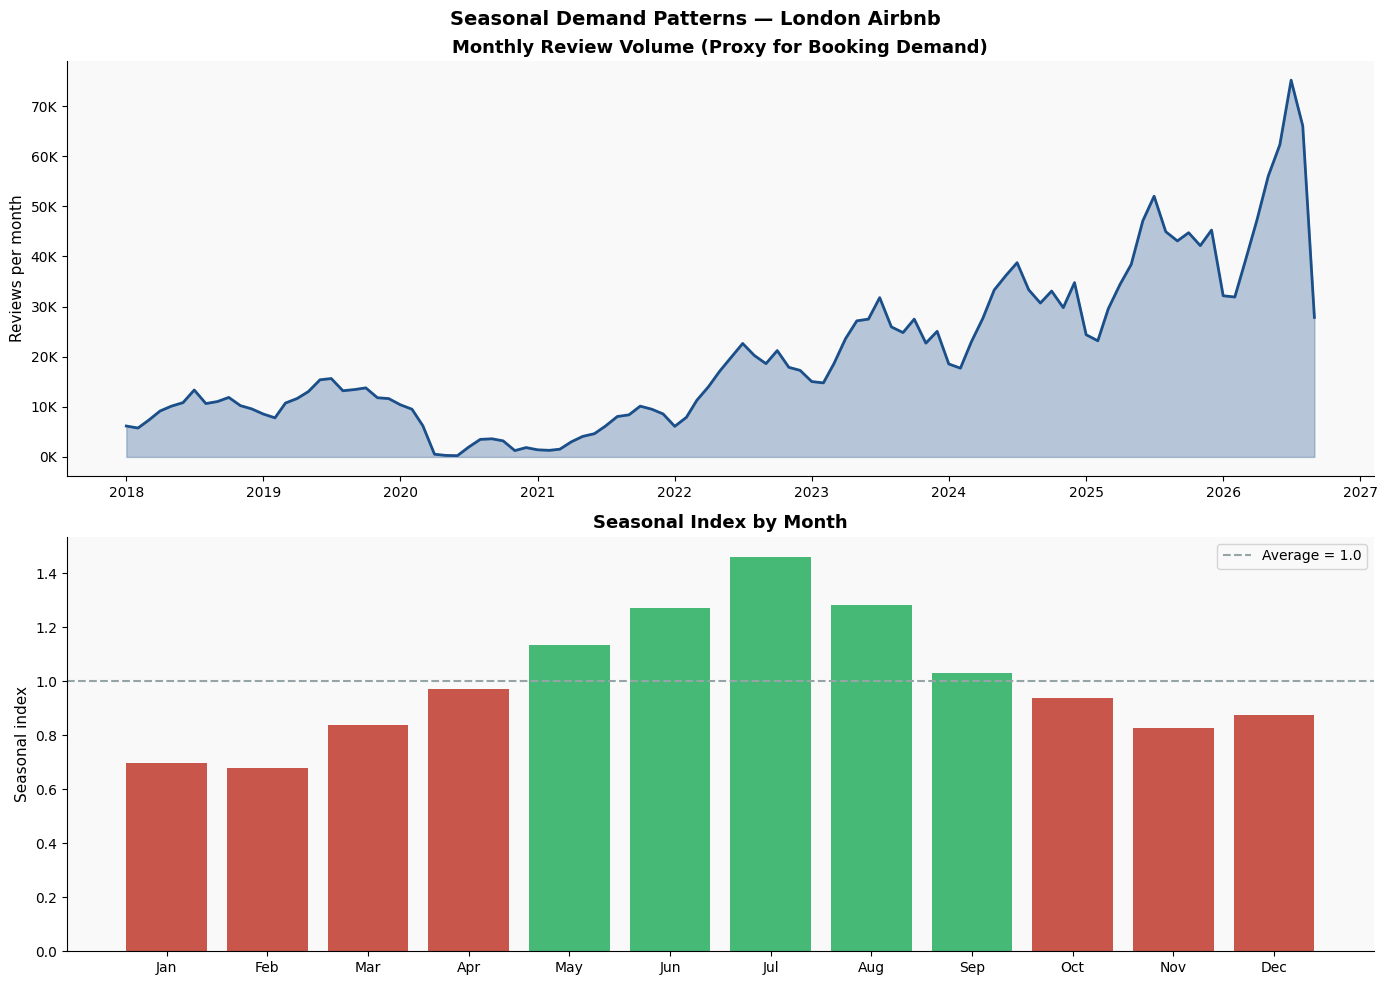

Peak demand month  : Jul  (index: 1.46)
Trough demand month: Feb  (index: 0.68)


In [7]:
reviews['year_month'] = reviews['date'].dt.to_period('M')
reviews['month']      = reviews['date'].dt.month
reviews['year']       = reviews['date'].dt.year

monthly_reviews = (reviews.groupby('year_month')
                   .size().reset_index(name='review_count'))
monthly_reviews['year_month_dt'] = monthly_reviews['year_month'].dt.to_timestamp()
monthly_reviews = monthly_reviews[monthly_reviews['year_month_dt'] >= '2018-01-01'].copy()

seasonal = (reviews[reviews['year'] >= 2018]
            .groupby('month').size().reset_index(name='reviews'))
seasonal['seasonal_index'] = seasonal['reviews'] / seasonal['reviews'].mean()

month_names = ['Jan','Feb','Mar','Apr','May','Jun',
               'Jul','Aug','Sep','Oct','Nov','Dec']

fig, axes = plt.subplots(2, 1, figsize=(14, 10))
fig.suptitle('Seasonal Demand Patterns — London Airbnb', fontsize=14, fontweight='bold')

axes[0].fill_between(monthly_reviews['year_month_dt'],
                     monthly_reviews['review_count'], alpha=0.3, color=BLUE)
axes[0].plot(monthly_reviews['year_month_dt'],
             monthly_reviews['review_count'], color=BLUE, lw=2)
axes[0].set_title('Monthly Review Volume (Proxy for Booking Demand)', fontweight='bold')
axes[0].set_ylabel('Reviews per month')
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{v/1000:.0f}K'))

axes[1].bar(range(1, 13), seasonal['seasonal_index'],
            color=[RED if v < 1 else GREEN for v in seasonal['seasonal_index']],
            alpha=0.85)
axes[1].axhline(1.0, color=GREY, lw=1.5, linestyle='--', label='Average = 1.0')
axes[1].set_xticks(range(1, 13))
axes[1].set_xticklabels(month_names)
axes[1].set_title('Seasonal Index by Month', fontweight='bold')
axes[1].set_ylabel('Seasonal index')
axes[1].legend()

plt.tight_layout()
plt.savefig(FIGURES / '07_seasonal_demand.png', dpi=150, bbox_inches='tight')
plt.show()

peak_month   = month_names[seasonal['seasonal_index'].idxmax()]
trough_month = month_names[seasonal['seasonal_index'].idxmin()]
print(f"Peak demand month  : {peak_month}  (index: {seasonal['seasonal_index'].max():.2f})")
print(f"Trough demand month: {trough_month}  (index: {seasonal['seasonal_index'].min():.2f})")

seasonal.to_csv(PROCESSED / 'seasonal_index.csv', index=False)


Occupancy by day of week and month

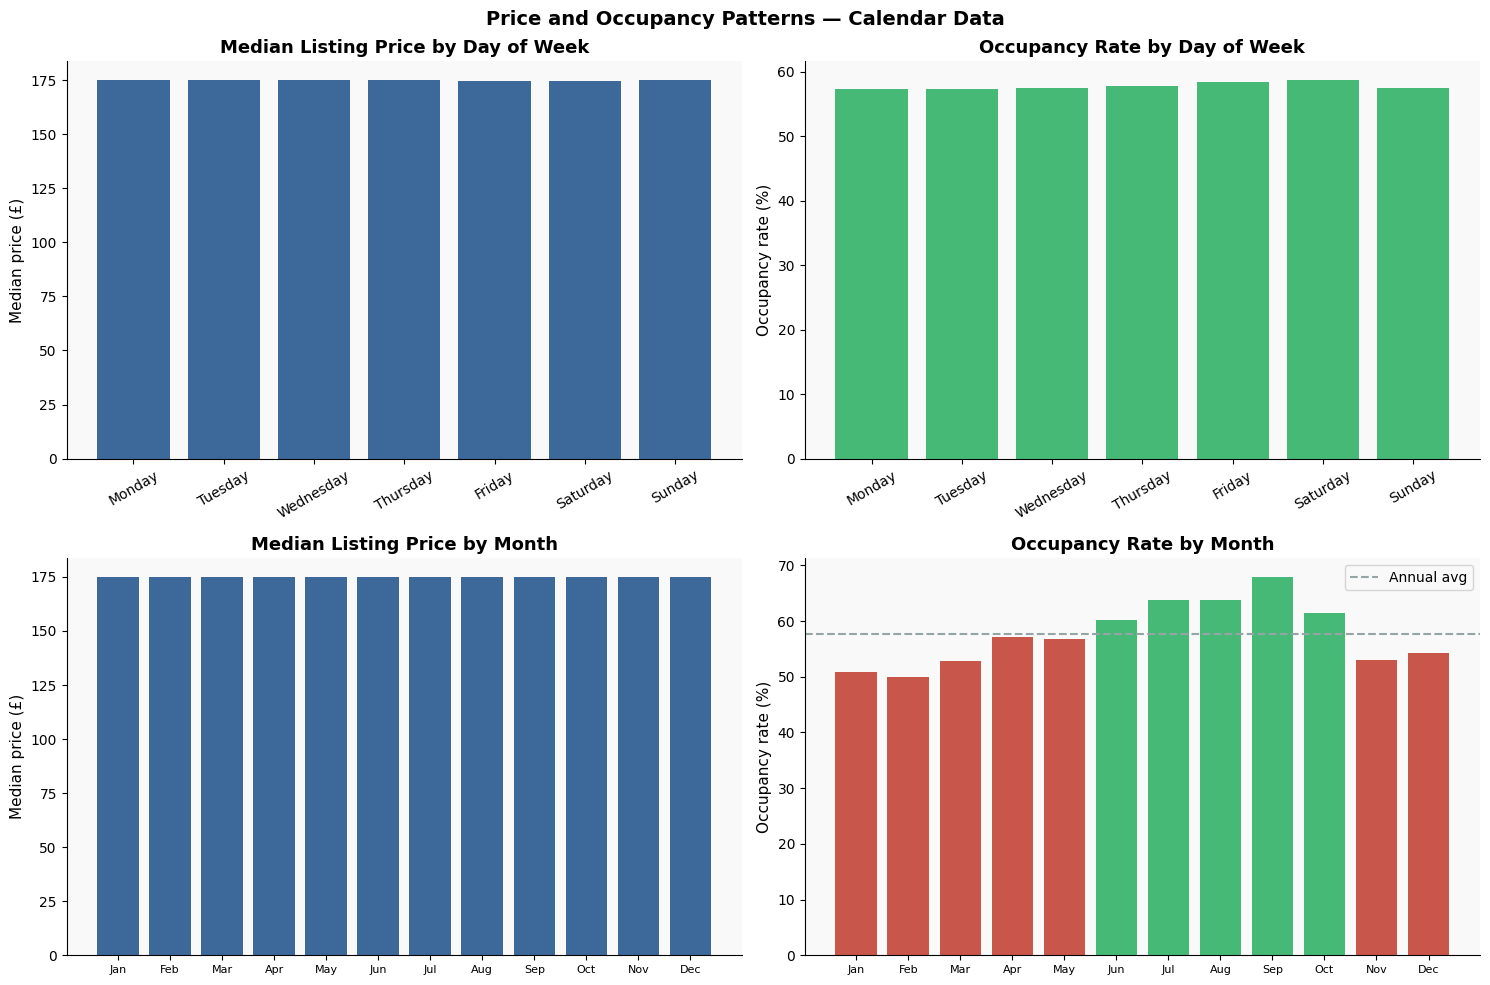

In [8]:
cal['day_of_week'] = cal['date'].dt.day_name()
cal['month']       = cal['date'].dt.month
cal['year']        = cal['date'].dt.year

cal_recent = cal[cal['year'] >= cal['year'].max() - 1].copy()

# Attach listing price (calendar has no price column)
price_lookup = listings[['id', 'price']].copy()
price_lookup['id'] = price_lookup['id'].astype(str)
cal_recent = cal_recent.merge(price_lookup.rename(columns={'id': 'listing_id'}),
                               on='listing_id', how='left')

dow_order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']

dow_stats = (cal_recent.groupby('day_of_week')
             .agg(avg_price=('price', 'median'),
                  occupancy=('is_booked', 'mean'))
             .reindex(dow_order).reset_index())

monthly_stats = (cal_recent.groupby('month')
                 .agg(avg_price=('price', 'median'),
                      occupancy=('is_booked', 'mean'))
                 .reset_index())

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
fig.suptitle('Price and Occupancy Patterns — Calendar Data', fontsize=14, fontweight='bold')

axes[0][0].bar(dow_stats['day_of_week'], dow_stats['avg_price'], color=BLUE, alpha=0.85)
axes[0][0].set_title('Median Listing Price by Day of Week', fontweight='bold')
axes[0][0].set_ylabel('Median price (£)')
axes[0][0].tick_params(axis='x', rotation=30)

axes[0][1].bar(dow_stats['day_of_week'], dow_stats['occupancy'] * 100, color=GREEN, alpha=0.85)
axes[0][1].set_title('Occupancy Rate by Day of Week', fontweight='bold')
axes[0][1].set_ylabel('Occupancy rate (%)')
axes[0][1].tick_params(axis='x', rotation=30)

axes[1][0].bar(monthly_stats['month'], monthly_stats['avg_price'], color=BLUE, alpha=0.85)
axes[1][0].set_xticks(range(1, 13))
axes[1][0].set_xticklabels(month_names, fontsize=8)
axes[1][0].set_title('Median Listing Price by Month', fontweight='bold')
axes[1][0].set_ylabel('Median price (£)')

axes[1][1].bar(monthly_stats['month'], monthly_stats['occupancy'] * 100,
               color=[RED if v < monthly_stats['occupancy'].mean() * 100 else GREEN
                      for v in monthly_stats['occupancy'] * 100],
               alpha=0.85)
axes[1][1].axhline(monthly_stats['occupancy'].mean() * 100,
                   color=GREY, lw=1.5, linestyle='--', label='Annual avg')
axes[1][1].set_xticks(range(1, 13))
axes[1][1].set_xticklabels(month_names, fontsize=8)
axes[1][1].set_title('Occupancy Rate by Month', fontweight='bold')
axes[1][1].set_ylabel('Occupancy rate (%)')
axes[1][1].legend()

plt.tight_layout()
plt.savefig(FIGURES / '08_price_occupancy_patterns.png', dpi=150, bbox_inches='tight')
plt.show()

dow_stats.to_csv(PROCESSED / 'demand_by_dow.csv', index=False)
monthly_stats.to_csv(PROCESSED / 'demand_by_month.csv', index=False)


Demand by neighbourhood

In [9]:
# Rebuild borough supply from listings
borough_supply = (listings.groupby(borough_col, dropna=True)
                  .agg(listings_count=('id', 'count'),
                       median_price=('price', 'median'))
                  .reset_index()
                  .rename(columns={'listings_count': 'listings'}))

print(f"Borough supply rows: {len(borough_supply)}")

# Match on string IDs to avoid dtype mismatch
listings_borough = listings[['id', borough_col]].copy()
listings_borough['id'] = listings_borough['id'].astype(str)

neigh_demand = (reviews
                .merge(listings_borough, left_on='listing_id', right_on='id', how='left')
                .dropna(subset=[borough_col])
                .groupby(borough_col)
                .agg(total_reviews=('listing_id', 'count'),
                     unique_listings=('listing_id', 'nunique'))
                .reset_index())

print(f"Neigh demand rows  : {len(neigh_demand)}")

demand_supply = neigh_demand.merge(
    borough_supply[[borough_col, 'listings', 'median_price']],
    on=borough_col, how='inner'
)
demand_supply['reviews_per_listing'] = (
    demand_supply['total_reviews'] / demand_supply['listings'].replace(0, np.nan)
)
demand_supply = demand_supply.sort_values('reviews_per_listing', ascending=False)

print(f"Demand-supply rows : {len(demand_supply)}")
print()
print(demand_supply[[borough_col, 'listings', 'total_reviews',
                     'reviews_per_listing', 'median_price']].to_string(index=False))

demand_supply.to_csv(PROCESSED / 'borough_demand.csv', index=False)


Borough supply rows: 33
Neigh demand rows  : 33
Demand-supply rows : 33

neighbourhood_cleansed  listings  total_reviews  reviews_per_listing  median_price
  Richmond upon Thames       762          33317            43.723097       167.785
             Islington      2495         105247            42.183166       182.000
        City of London       502          20209            40.256972       278.250
                Camden      4288         168529            39.302472       207.500
               Lambeth      2827         109558            38.754156       153.000
             Southwark      3029         116845            38.575437       157.670
         Tower Hamlets      3874         133292            34.406815       161.415
           Westminster      7931         271773            34.267179       281.000
Hammersmith and Fulham      2678          87616            32.716953       184.000
              Haringey      1421          46370            32.631949       130.500
Kensington and

Supply-Demand balance score

Supply-Demand Balance by Borough:
neighbourhood_cleansed  balance_score  market_status  reviews_per_listing  listings
  Richmond upon Thames       0.951048 Under-supplied            43.723097       762
        City of London       0.873518 Under-supplied            40.256972       502
             Islington       0.671377 Under-supplied            42.183166      2495
  Kingston upon Thames       0.517036 Under-supplied            29.058568       461
               Lambeth       0.516511 Under-supplied            38.754156      2827
              Haringey       0.505169 Under-supplied            32.631949      1421
             Southwark       0.483938 Under-supplied            38.575437      3029
              Hounslow       0.483449 Under-supplied            30.042977       954
            Hillingdon       0.431297 Under-supplied            27.604250       753
                Ealing       0.362663 Under-supplied            29.002483      1611
Hammersmith and Fulham       0.341162 Unde

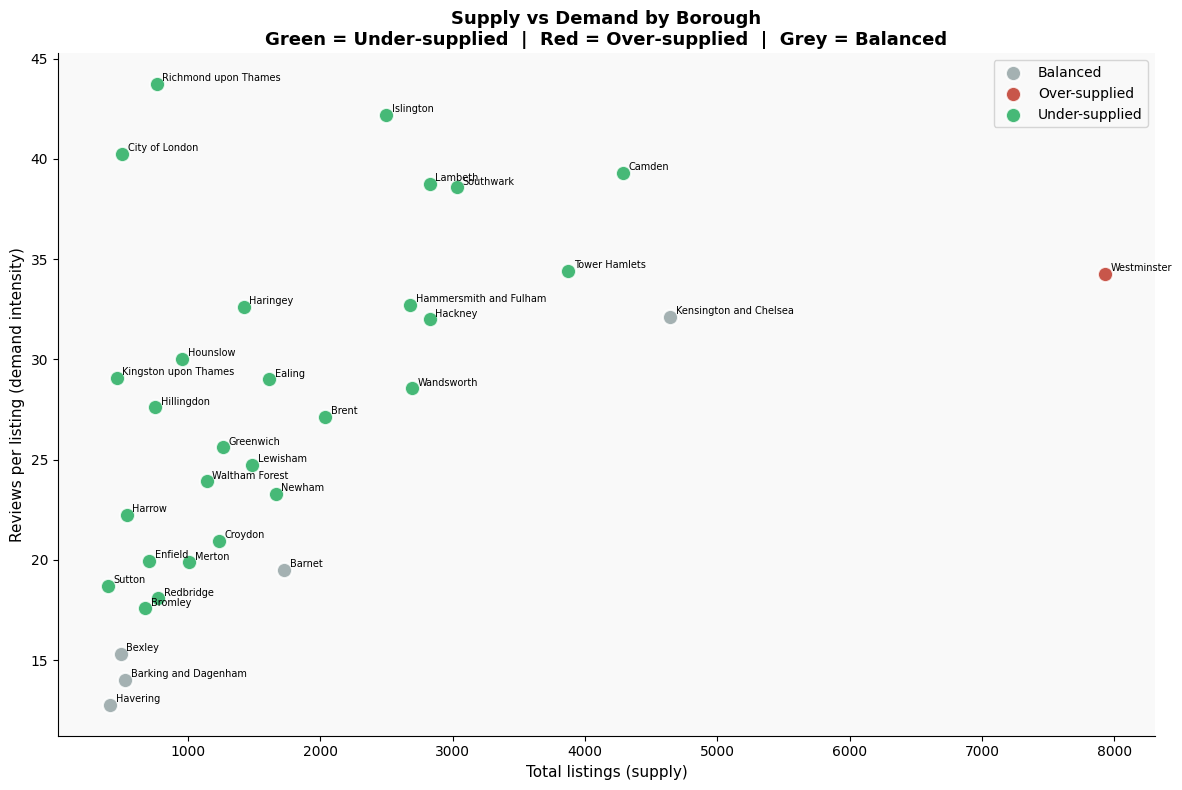

In [10]:
scaler  = MinMaxScaler()
balance = demand_supply.copy()
balance['demand_score']  = scaler.fit_transform(balance[['reviews_per_listing']])
balance['supply_score']  = scaler.fit_transform(balance[['listings']])
balance['balance_score'] = balance['demand_score'] - balance['supply_score']

balance['market_status'] = balance['balance_score'].apply(
    lambda v: 'Under-supplied' if v > 0.1 else 'Over-supplied' if v < -0.1 else 'Balanced'
)

print("Supply-Demand Balance by Borough:")
print(balance[[borough_col, 'balance_score', 'market_status',
               'reviews_per_listing', 'listings']]
      .sort_values('balance_score', ascending=False).to_string(index=False))

colors_bal = {'Under-supplied': GREEN, 'Over-supplied': RED, 'Balanced': GREY}

fig, ax = plt.subplots(figsize=(12, 8))
for status, grp in balance.groupby('market_status'):
    ax.scatter(grp['listings'], grp['reviews_per_listing'],
               c=colors_bal[status], s=120, alpha=0.85,
               label=status, edgecolors='white', lw=1.5)
    for _, row in grp.iterrows():
        ax.annotate(row[borough_col], (row['listings'], row['reviews_per_listing']),
                    fontsize=7, xytext=(4, 2), textcoords='offset points')

ax.set_title('Supply vs Demand by Borough\n'
             'Green = Under-supplied  |  Red = Over-supplied  |  Grey = Balanced',
             fontweight='bold')
ax.set_xlabel('Total listings (supply)')
ax.set_ylabel('Reviews per listing (demand intensity)')
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES / '09_supply_demand_balance.png', dpi=150, bbox_inches='tight')
plt.show()

balance.to_csv(PROCESSED / 'borough_balance.csv', index=False)


Review ratings analysis

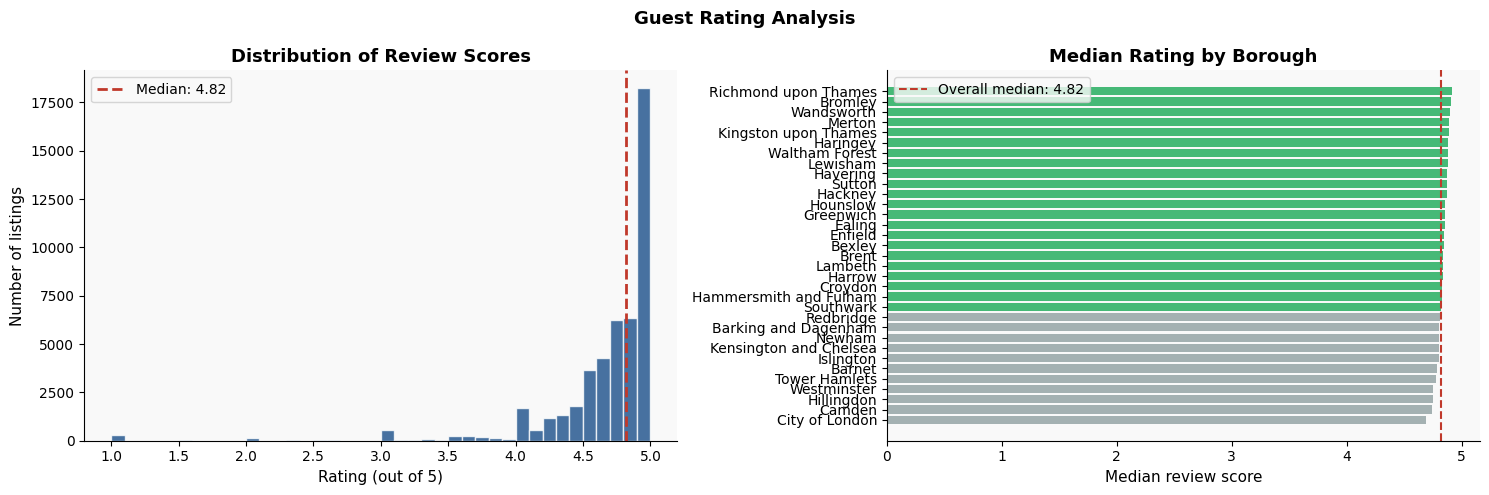

Overall median rating : 4.82
% listings rated 4.8+ : 53.7%
% listings rated < 4.0: 4.8%


In [11]:
if 'review_scores_rating' in listings.columns:
    ratings = listings['review_scores_rating'].dropna()

    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    fig.suptitle('Guest Rating Analysis', fontsize=13, fontweight='bold')

    axes[0].hist(ratings, bins=40, color=BLUE, alpha=0.8, edgecolor='white', lw=0.3)
    axes[0].axvline(ratings.median(), color=RED, lw=2, linestyle='--',
                    label=f'Median: {ratings.median():.2f}')
    axes[0].set_title('Distribution of Review Scores', fontweight='bold')
    axes[0].set_xlabel('Rating (out of 5)')
    axes[0].set_ylabel('Number of listings')
    axes[0].legend()

    borough_ratings = (listings.groupby(borough_col)['review_scores_rating']
                       .median().sort_values(ascending=True))
    axes[1].barh(borough_ratings.index, borough_ratings.values,
                 color=[GREEN if v >= ratings.median() else GREY
                        for v in borough_ratings.values],
                 alpha=0.85)
    axes[1].axvline(ratings.median(), color=RED, lw=1.5, linestyle='--',
                    label=f'Overall median: {ratings.median():.2f}')
    axes[1].set_title('Median Rating by Borough', fontweight='bold')
    axes[1].set_xlabel('Median review score')
    axes[1].legend()

    plt.tight_layout()
    plt.savefig(FIGURES / '10_ratings_analysis.png', dpi=150, bbox_inches='tight')
    plt.show()

    print(f"Overall median rating : {ratings.median():.2f}")
    print(f"% listings rated 4.8+ : {(ratings >= 4.8).mean()*100:.1f}%")
    print(f"% listings rated < 4.0: {(ratings < 4.0).mean()*100:.1f}%")
else:
    print("review_scores_rating column not found — skipping ratings analysis")


Save all outputs and download

In [12]:
import shutil

listings.to_csv(PROCESSED / 'listings_with_occupancy.csv', index=False)

print("Saved files:")
for f in sorted(PROCESSED.glob('*.csv')):
    print(f"  {f.name:<50}  {f.stat().st_size/1024:6.1f} KB")

shutil.make_archive('/content/marketiq_nb02', 'zip', '/content')
files.download('/content/marketiq_nb02.zip')
print("\nDownloaded marketiq_nb02.zip")


Saved files:
  borough_balance.csv                                    4.1 KB
  borough_demand.csv                                     1.8 KB
  demand_by_dow.csv                                      0.3 KB
  demand_by_month.csv                                    0.3 KB
  listings_with_occupancy.csv                         13982.3 KB
  seasonal_index.csv                                     0.4 KB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Downloaded marketiq_nb02.zip
